# Lab 12-03 · Frequency Response: Device Capacitances, Miller Effect, Poles and Zeros

Companion to [chapter 12-03](../../chapters/12-03-frequency-response-miller-poles-zeros.md). Four parts: a MOSFET's short-circuit current gain and $f_T$; the common-source stage against its estimates; common-source, common-gate and cascode stages compared; and a source follower driven from a resistive source. Run the cells in order.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

TP = 2 * math.pi


def solve(nodes, elems, fixed, f):
    """Complex nodal analysis at frequency f. ('R', a, b, ohms), ('C', a, b, farads),
    ('G', d, s, cp, cn, gm): current gm*(v(cp) - v(cn)) leaves d and enters s; ('I', a, b, amps)."""
    idx = {n: i for i, n in enumerate(nodes)}
    Y = np.zeros((len(nodes), len(nodes)), complex); b = np.zeros(len(nodes), complex)
    fx = dict(fixed); fx.setdefault('0', 0.0); s = 1j * TP * f
    def add(i, j, val):
        if i not in idx: return
        if j in idx: Y[idx[i], idx[j]] += val
        else: b[idx[i]] -= val * fx[j]
    for e in elems:
        if e[0] in ('R', 'C'):
            a, c, y = e[1], e[2], (1 / e[3] if e[0] == 'R' else s * e[3])
            add(a, a, y); add(a, c, -y); add(c, c, y); add(c, a, -y)
        elif e[0] == 'G':
            d, sn, cp, cn, gm = e[1:]
            add(d, cp, gm); add(d, cn, -gm); add(sn, cp, -gm); add(sn, cn, gm)
        elif e[0] == 'I':
            if e[1] in idx: b[idx[e[1]]] -= e[3]
            if e[2] in idx: b[idx[e[2]]] += e[3]
    x = np.linalg.solve(Y, b)
    return {n: x[idx[n]] for n in nodes}


gm, Cgs, Cgd, CL, RL = 1e-3, 72.6667e-15, 6e-15, 100e-15, 20e3

## Part 1 · Short-circuit current gain and $f_T$

Drive the gate with a current, short the drain, and plot the controlled source's current over the input current.

unity current gain near 2.022 GHz (formula: 2.023 GHz)


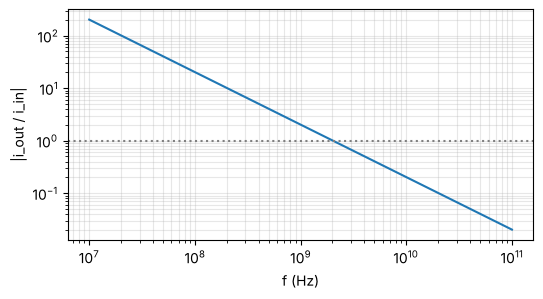

In [2]:
f = np.logspace(7, 11, 400)
beta = []
for fi in f:
    vg = solve(['g'], [('C', 'g', '0', Cgs), ('C', 'g', 'd', Cgd), ('I', '0', 'g', 1.0)], {'d': 0.0}, fi)['g']
    beta.append(abs(gm * vg))
beta = np.array(beta)
fT = f[np.argmin(np.abs(beta - 1))]
print(f"unity current gain near {fT / 1e9:.3f} GHz (formula: {gm / (TP * (Cgs + Cgd)) / 1e9:.3f} GHz)")
plt.figure(figsize=(6, 3)); plt.loglog(f, beta); plt.axhline(1, ls=':', color='0.5')
plt.xlabel('f (Hz)'); plt.ylabel('|i_out / i_in|'); plt.grid(True, which='both', alpha=0.3); plt.show()

## Part 2 · The common-source stage against its estimates (the chapter's guided exercise)

**Predict first:** if the source resistance is cut from 10 kΩ to 1 kΩ, does the bandwidth rise tenfold?

In [3]:
def cs(fi, RS, CL_=CL):
    el = [('R', 'vs', 'g', RS), ('C', 'g', '0', Cgs), ('C', 'g', 'o', Cgd), ('G', 'o', '0', 'g', '0', gm),
          ('R', 'o', '0', RL), ('C', 'o', '0', CL_)]
    return solve(['g', 'o'], el, {'vs': 1.0}, fi)['o']


def f3(fun):
    a0 = abs(fun(1.0))
    return brentq(lambda x: abs(fun(x)) - a0 / math.sqrt(2), 1e5, 1e11)


print(" R_S (kOhm)   exact f3 (MHz)   Miller-only (MHz)   1/(2 pi b1) (MHz)")
for RS in (100, 1e3, 10e3, 100e3):
    Cm = Cgs + Cgd * (1 + gm * RL)
    b1 = RS * Cm + RL * (Cgd + CL)
    print(f"{RS / 1e3:10.1f}   {f3(lambda x: cs(x, RS)) / 1e6:14.2f}   {1 / (TP * RS * Cm) / 1e6:17.2f}   {1 / (TP * b1) / 1e6:17.2f}")

 R_S (kOhm)   exact f3 (MHz)   Miller-only (MHz)   1/(2 pi b1) (MHz)
       0.1            74.65             8011.15               74.38
       1.0            70.83              801.12               68.64
      10.0            42.93               80.11               38.76
     100.0             7.50                8.01                7.24


**What to notice.** At low $R_S$ the output node limits the bandwidth and the Miller-only estimate is far too optimistic; at high $R_S$ the Miller term dominates and both estimates converge on the exact value.

## Part 3 · Common source, common gate and cascode from one device

In [4]:
RS = 10e3
cg = lambda x: solve(['sn', 'o'], [('R', 'vs', 'sn', RS), ('C', 'sn', '0', Cgs), ('G', 'o', 'sn', '0', 'sn', gm),
                                   ('R', 'o', '0', RL), ('C', 'o', '0', CL + Cgd)], {'vs': 1.0}, x)['o']
Cx = Cgs + 10e-15
cc = lambda x: solve(['g', 'x', 'o'], [('R', 'vs', 'g', RS), ('C', 'g', '0', Cgs), ('C', 'g', 'x', Cgd),
                                       ('G', 'x', '0', 'g', '0', gm), ('C', 'x', '0', Cx), ('G', 'o', 'x', '0', 'x', gm),
                                       ('C', 'o', '0', Cgd), ('R', 'o', '0', RL), ('C', 'o', '0', CL)], {'vs': 1.0}, x)['o']
for name, fun in (('common source', lambda x: cs(x, RS)), ('common gate', cg), ('cascode', cc)):
    print(f"{name:14s} gain {abs(fun(1.0)):6.3f}, f3 {f3(fun) / 1e6:7.2f} MHz, GBW {abs(fun(1.0)) * f3(fun) / 1e6:7.1f} MHz")

common source  gain 20.000, f3   42.93 MHz, GBW   858.6 MHz
common gate    gain  1.818, f3   75.00 MHz, GBW   136.4 MHz
cascode        gain 20.000, f3   66.07 MHz, GBW  1321.5 MHz


**What to notice.** The common-gate stage is fast but, from a 10 kΩ source, has little gain; the cascode keeps the common-source gain and gets most of the common-gate bandwidth.

## Part 4 · A source follower from a resistive source

A follower ($g_m$ = 1 mA/V, $C_{gs}$ = 72.67 fF) drives $C_L$ from a source resistance $R_S$; $C_{gd}$ goes from the gate to AC ground. As $R_S$ grows, the response develops a peak.

R_S =   0.1 kOhm: peak -0.02 dB
R_S =   2.0 kOhm: peak -0.01 dB
R_S =  10.0 kOhm: peak  0.16 dB
R_S =  30.0 kOhm: peak  2.59 dB


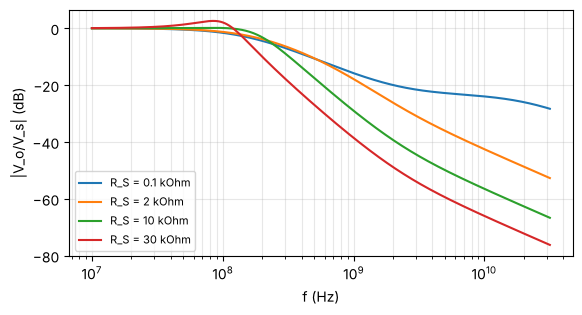

In [5]:
def fol(x, RS, CL_):
    return solve(['g', 'o'], [('R', 'vs', 'g', RS), ('C', 'g', '0', Cgd), ('C', 'g', 'o', Cgs),
                              ('G', '0', 'o', 'g', 'o', gm), ('C', 'o', '0', CL_)], {'vs': 1.0}, x)['o']


ff = np.logspace(7, 10.5, 600)
plt.figure(figsize=(6.5, 3.2))
for RS in (100, 2e3, 10e3, 30e3):
    mag = np.array([abs(fol(x, RS, 1e-12)) for x in ff])
    print(f"R_S = {RS / 1e3:5.1f} kOhm: peak {20 * math.log10(mag.max()):5.2f} dB")
    plt.semilogx(ff, 20 * np.log10(mag), label=f"R_S = {RS / 1e3:g} kOhm")
plt.xlabel('f (Hz)'); plt.ylabel('|V_o/V_s| (dB)'); plt.legend(fontsize=8); plt.grid(True, which='both', alpha=0.3)
plt.show()

**What to take away.** Every node is an RC; a capacitor across an inverting gain is multiplied by it; the dominant-pole estimate needs every node's time constant, not only the Miller one; and cascodes and common-gate stages buy bandwidth by removing the Miller multiplication. Followers driven from high resistance can peak (12-04).